# Tree based methods

In [ ]:
%matplotlib inline
from pylab import *
import pandas as pd
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

# URL of the Spam dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"

# Feature names (obtained from spambase.names file, refer to previous

##   Importation des données Spam

> Télécharger [les donnnées Spam](https://archive.ics.uci.edu/ml/datasets/spambase) depuis la plateforme UCI. Importer les données sous python, par exemple en utilisant pandas. Donner son label à chaque variable. La variable cible $Y$ qui indique la présence d'un spam est en dernière position dans la base de données. Créer deux tableaux numpy X_Spam and Y_Spam pour ce problème de classification.

#### Importation du nom des variables depuis "spambase.names"

Le fichier des noms de variables (prêt à l'emploi, pour vous faire gagner du temps) est disponible [ici](https://box.ec-nantes.fr:443/index.php/s/5SZxSp5ZSFEeGZR).

In [ ]:
import pandas as pd

# URL of the spambase.names file
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.names"

# Read the file directly from the URL
features_names = pd.read_csv(url, delim_whitespace=True, header=None, skiprows=33)
print(features_names)
len( features_names)

<ipython-input-5-9cf3b44c2461>:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  features_names = pd.read_csv(url, delim_whitespace=True, header=None, skiprows=33)


                              0            1
0               word_freq_make:  continuous.
1            word_freq_address:  continuous.
2                word_freq_all:  continuous.
3                 word_freq_3d:  continuous.
4                word_freq_our:  continuous.
5               word_freq_over:  continuous.
6             word_freq_remove:  continuous.
7           word_freq_internet:  continuous.
8              word_freq_order:  continuous.
9               word_freq_mail:  continuous.
10           word_freq_receive:  continuous.
11              word_freq_will:  continuous.
12            word_freq_people:  continuous.
13            word_freq_report:  continuous.
14         word_freq_addresses:  continuous.
15              word_freq_free:  continuous.
16          word_freq_business:  continuous.
17             word_freq_email:  continuous.
18               word_freq_you:  continuous.
19            word_freq_credit:  continuous.
20              word_freq_your:  continuous.
21        

57

In [ ]:

print(features_names.values[:,0])

['word_freq_make:' 'word_freq_address:' 'word_freq_all:' 'word_freq_3d:'
 'word_freq_our:' 'word_freq_over:' 'word_freq_remove:'
 'word_freq_internet:' 'word_freq_order:' 'word_freq_mail:'
 'word_freq_receive:' 'word_freq_will:' 'word_freq_people:'
 'word_freq_report:' 'word_freq_addresses:' 'word_freq_free:'
 'word_freq_business:' 'word_freq_email:' 'word_freq_you:'
 'word_freq_credit:' 'word_freq_your:' 'word_freq_font:' 'word_freq_000:'
 'word_freq_money:' 'word_freq_hp:' 'word_freq_hpl:' 'word_freq_george:'
 'word_freq_650:' 'word_freq_lab:' 'word_freq_labs:' 'word_freq_telnet:'
 'word_freq_857:' 'word_freq_data:' 'word_freq_415:' 'word_freq_85:'
 'word_freq_technology:' 'word_freq_1999:' 'word_freq_parts:'
 'word_freq_pm:' 'word_freq_direct:' 'word_freq_cs:' 'word_freq_meeting:'
 'word_freq_original:' 'word_freq_project:' 'word_freq_re:'
 'word_freq_edu:' 'word_freq_table:' 'word_freq_conference:'
 'char_freq_;:' 'char_freq_(:' 'char_freq_[:' 'char_freq_!:'
 'char_freq_$:' 'char_f

#### Importation de la table de données au format pandas

In [ ]:
data_path = url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"
Spam_data =pd.read_csv(data_path, header=None)

In [ ]:
print(Spam_data.shape)
print(Spam_data.head())

(4601, 58)
     0     1     2    3     4     5     6     7     8     9   ...    48  \
0  0.00  0.64  0.64  0.0  0.32  0.00  0.00  0.00  0.00  0.00  ...  0.00   
1  0.21  0.28  0.50  0.0  0.14  0.28  0.21  0.07  0.00  0.94  ...  0.00   
2  0.06  0.00  0.71  0.0  1.23  0.19  0.19  0.12  0.64  0.25  ...  0.01   
3  0.00  0.00  0.00  0.0  0.63  0.00  0.31  0.63  0.31  0.63  ...  0.00   
4  0.00  0.00  0.00  0.0  0.63  0.00  0.31  0.63  0.31  0.63  ...  0.00   

      49   50     51     52     53     54   55    56  57  
0  0.000  0.0  0.778  0.000  0.000  3.756   61   278   1  
1  0.132  0.0  0.372  0.180  0.048  5.114  101  1028   1  
2  0.143  0.0  0.276  0.184  0.010  9.821  485  2259   1  
3  0.137  0.0  0.137  0.000  0.000  3.537   40   191   1  
4  0.135  0.0  0.135  0.000  0.000  3.537   40   191   1  

[5 rows x 58 columns]


In [ ]:
Spam_data.describe()  # le summary de pandas

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
count,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,...,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000
mean,0.104553,0.213015,0.280656,0.065425,0.312223,0.095901,0.114208,0.105295,0.090067,0.239413,...,0.038575,0.139030,0.016976,0.269071,0.075811,0.044238,5.191515,52.172789,283.289285,0.394045
std,0.305358,1.290575,0.504143,1.395151,0.672513,0.273824,0.391441,0.401071,0.278616,0.644755,...,0.243471,0.270355,0.109394,0.815672,0.245882,0.429342,31.729449,194.891310,606.347851,0.488698
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.588000,6.000000,35.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.065000,0.000000,0.000000,0.000000,0.000000,2.276000,15.000000,95.000000,0.000000
75%,0.000000,0.000000,0.420000,0.000000,0.380000,0.000000,0.000000,0.000000,0.000000,0.160000,...,0.000000,0.188000,0.000000,0.315000,0.052000,0.000000,3.706000,43.000000,266.000000,1.000000
max,4.540000,14.280000,5.100000,42.810000,10.000000,5.880000,7.270000,11.110000,5.260000,18.180000,...,4.385000,9.752000,4.081000,32.478000,6.003000,19.829000,1102.500000,9989.000000,15841.000000,1.000000


In [ ]:
X_Spam = Spam_data.values[:,0:57]
Y_Spam = Spam_data.values[:,57]

Y_Spam

array([1., 1., 1., ..., 0., 0., 0.])

## Arbres décisionnels CART

> Ajuster un arbre de classification sur les données Spam avec la fonction [tree.DecisionTreeClassifier](http://scikit-learn.org/stable/modules/tree.html#classification) (lire la documentation de cette fonction).

[Text(0.5555555555555556, 0.875, 'x[52] <= 0.056\ngini = 0.478\nsamples = 4601\nvalue = [2788.0, 1813.0]'),
 Text(0.3333333333333333, 0.625, 'x[6] <= 0.055\ngini = 0.36\nsamples = 3471\nvalue = [2655, 816]'),
 Text(0.4444444444444444, 0.75, 'True  '),
 Text(0.2222222222222222, 0.375, 'x[51] <= 0.378\ngini = 0.275\nsamples = 3141\nvalue = [2625, 516]'),
 Text(0.1111111111111111, 0.125, 'gini = 0.181\nsamples = 2737\nvalue = [2462, 275]'),
 Text(0.3333333333333333, 0.125, 'gini = 0.481\nsamples = 404\nvalue = [163, 241]'),
 Text(0.4444444444444444, 0.375, 'gini = 0.165\nsamples = 330\nvalue = [30, 300]'),
 Text(0.7777777777777778, 0.625, 'x[24] <= 0.4\ngini = 0.208\nsamples = 1130\nvalue = [133, 997]'),
 Text(0.6666666666666667, 0.75, '  False'),
 Text(0.6666666666666666, 0.375, 'gini = 0.123\nsamples = 1060\nvalue = [70, 990]'),
 Text(0.8888888888888888, 0.375, 'gini = 0.18\nsamples = 70\nvalue = [63, 7]')]

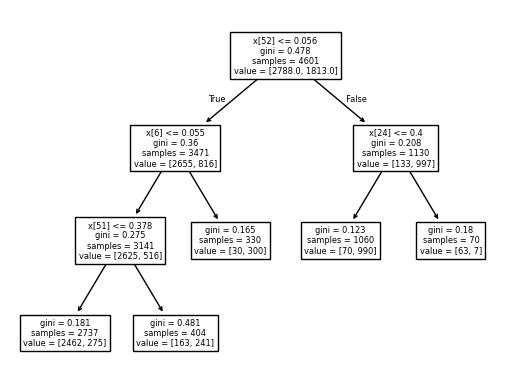

In [ ]:
from sklearn import tree
# Create and train the decision tree classifier
tree_classifier = tree.DecisionTreeClassifier(max_leaf_nodes = 5)
tree_classifier = tree_classifier.fit(X_Spam, Y_Spam)
# Plot the tree
tree.plot_tree(tree_classifier)

> Représenter l'arbre de classification avec 5 noeuds terminaux (`max_leaf_nodes`)  à l'aide de la fonction `tree.plot_tree`.

> Comparer les performances de l'arbre de classification pour plusieurs choix de nombre maximal de noeuds (`max_leaf_nodes=`). Utiliser une procédure 5-folds avec la fonction `GridSearchCV` pour évaluer  et comparer les erreurs de généralisation. Pensez à imposer une permutation aléatoire des blocs.

/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


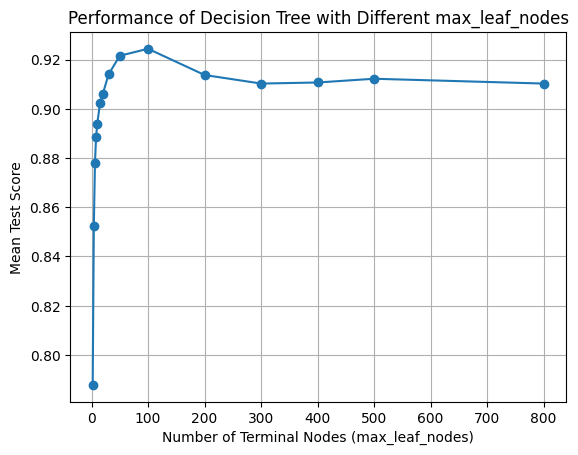

In [ ]:
maxnodes = [2, 4, 6, 8, 10, 15, 20, 30, 50, 100, 200, 300, 400, 500, 800]
param_grid = {'max_leaf_nodes': maxnodes}
# Create the decision tree classifier
tree_classifier = DecisionTreeClassifier()
#  5-fold
cv = KFold(n_splits=5, shuffle=True)

Cart_grid = GridSearchCV(estimator=tree_classifier, param_grid=param_grid, cv=cv)

# Fit the GridSearchCV object to the data
Cart_grid.fit(X_Spam, Y_Spam)

# Extract mean test scores
mean_test_scores = Cart_grid.cv_results_['mean_test_score']

# Plot the results
plt.plot(maxnodes, mean_test_scores, marker='o')
plt.xlabel('Number of Terminal Nodes (max_leaf_nodes)')
plt.ylabel('Mean Test Score')
plt.title('Performance of Decision Tree with Different max_leaf_nodes')
plt.grid(True)
plt.show()

> Si on appelle `Cart_grid` le résultat de `GridSearchCV`, le détail des scores obtenus sur la grille de paramètres pour chacun des folds est disponible dans le dictionnaire `Cart_grid.cv_results_`.    
> - Afficher l'ensemble des attributs de `Cart_grid.cv_results_`.    
> - Extraire du résultat de gridsearchCV le vecteur des scores moyens obtenus par la procédure 5 folds pour chaque paramètre choisi (attribut `mean_test_score`).  
> - Representer le score (moyen) en fonction du nombre de noeuds terminaux.

Attributes of Cart_grid.cv_results_:
mean_fit_time
std_fit_time
mean_score_time
std_score_time
param_max_leaf_nodes
params
split0_test_score
split1_test_score
split2_test_score
split3_test_score
split4_test_score
mean_test_score
std_test_score
rank_test_score

Mean test scores: [0.78787259 0.85220436 0.8780718  0.88850186 0.89371855 0.90241373
 0.90610914 0.913935   0.92153921 0.92436388 0.91371477 0.91023698
 0.91067106 0.91219303 0.91023462]


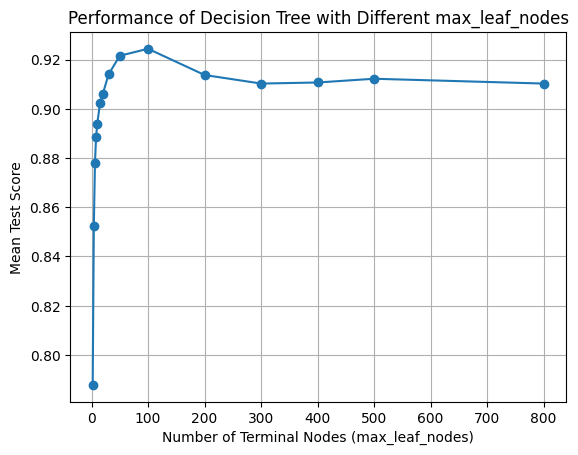

In [ ]:


# Display all attributes of Cart_grid.cv_results_
print("Attributes of Cart_grid.cv_results_:")
for attribute in Cart_grid.cv_results_:
    print(attribute)

# Extrac mean test scores
mean_test_scores = Cart_grid.cv_results_['mean_test_score']
print("\nMean test scores:", mean_test_scores)

# Plot the results
plt.plot(maxnodes, mean_test_scores, marker='o')
plt.xlabel('Number of Terminal Nodes (max_leaf_nodes)')
plt.ylabel('Mean Test Score')
plt.title('Performance of Decision Tree with Different max_leaf_nodes')
plt.grid(True)
plt.show()

Les performances sont très bonnes car le problème est assez facile mais on observe quand même l'effet du sur-apprentissage pour les arbres les plus developpés.

> Illustrer l'instabilité des arbres CART sur des arbres de petites tailles (prendre par exemple `max_leaf_nodes=6`). On pourra tirer des échantillons aléatoirement avec remise dans les données initiales (précédure bootstrap) en utilisant la fonction [`resample`](https://scikit-learn.org/stable/modules/generated/sklearn.utils.resample.html) et comparer finalement (graphiquement) les arbres de décision ainsi ajustés.

> **Bonus :** Cette fois pour des arbres à 20 noeuds terminiaux, et pour 10 échantillons bootstrap, extraire de la structure des arbres CART la liste des variables de découpage (voir par exemple [ici](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html)). Comparer ces listes de variables de découpage.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import resample

# taille de l'echantillon
n = 10
# Nombre maximal de nœuds
max_leaf_nodes = 20

# Stockage des varaibles de decoupage
splitting_variables_list = []

#  bootstrap
for i in range(n):
    X_bootstrap, Y_bootstrap = resample(X_Spam, Y_Spam, random_state=i)

    tree_classifier = DecisionTreeClassifier(max_leaf_nodes=max_leaf_nodes)
    tree_classifier.fit(X_bootstrap, Y_bootstrap)
    splitting_variables = tree_classifier.tree_.feature
    splitting_variable_names = [features_names.values[var,0] if var != -2 else None for var in splitting_variables]
    splitting_variables_list.append(splitting_variable_names)

#  Comparer les variables de découpage
#premières variables de découpage de chaque arbre  car c'est une approche pragmatique qui permet d'identifier les variables les plus importantes et de simplifier l'analyse
for i, splitting_vars in enumerate(splitting_variables_list):
    print(f"Échantillon Bootstrap {i + 1} : {splitting_vars[:5]}...")

Échantillon Bootstrap 1 : ['char_freq_!:', 'word_freq_remove:', 'capital_run_length_average:', 'word_freq_free:', 'word_freq_hp:']...
Échantillon Bootstrap 2 : ['char_freq_!:', 'word_freq_remove:', 'capital_run_length_longest:', 'word_freq_free:', 'word_freq_hp:']...
Échantillon Bootstrap 3 : ['char_freq_!:', 'word_freq_remove:', 'capital_run_length_longest:', 'word_freq_free:', 'word_freq_hp:']...
Échantillon Bootstrap 4 : ['char_freq_$:', 'word_freq_remove:', 'word_freq_hp:', 'char_freq_!:', 'word_freq_george:']...
Échantillon Bootstrap 5 : ['char_freq_$:', 'word_freq_remove:', 'word_freq_hp:', 'char_freq_!:', 'word_freq_george:']...
Échantillon Bootstrap 6 : ['char_freq_!:', 'word_freq_remove:', 'capital_run_length_average:', 'word_freq_your:', 'word_freq_hp:']...
Échantillon Bootstrap 7 : ['char_freq_$:', 'word_freq_remove:', 'word_freq_hp:', 'char_freq_!:', 'word_freq_george:']...
Échantillon Bootstrap 8 : ['char_freq_$:', 'word_freq_remove:', 'word_freq_hp:', 'char_freq_!:', 'wor


Apparition des variables de découpage :
char_freq_!:: 19 fois
word_freq_remove:: 16 fois
capital_run_length_average:: 9 fois
word_freq_free:: 18 fois
word_freq_hp:: 19 fois
word_freq_money:: 8 fois
word_freq_george:: 16 fois
char_freq_$:: 11 fois
word_freq_meeting:: 7 fois
word_freq_business:: 3 fois
word_freq_edu:: 13 fois
word_freq_internet:: 5 fois
word_freq_our:: 11 fois
capital_run_length_longest:: 7 fois
word_freq_your:: 3 fois
word_freq_you:: 5 fois
word_freq_project:: 1 fois
word_freq_1999:: 2 fois
word_freq_addresses:: 1 fois
capital_run_length_total:: 4 fois
word_freq_email:: 1 fois
word_freq_000:: 3 fois
word_freq_3d:: 1 fois
word_freq_conference:: 1 fois
word_freq_re:: 1 fois
word_freq_font:: 1 fois
char_freq_;:: 1 fois
word_freq_pm:: 1 fois
word_freq_over:: 1 fois
char_freq_(:: 1 fois


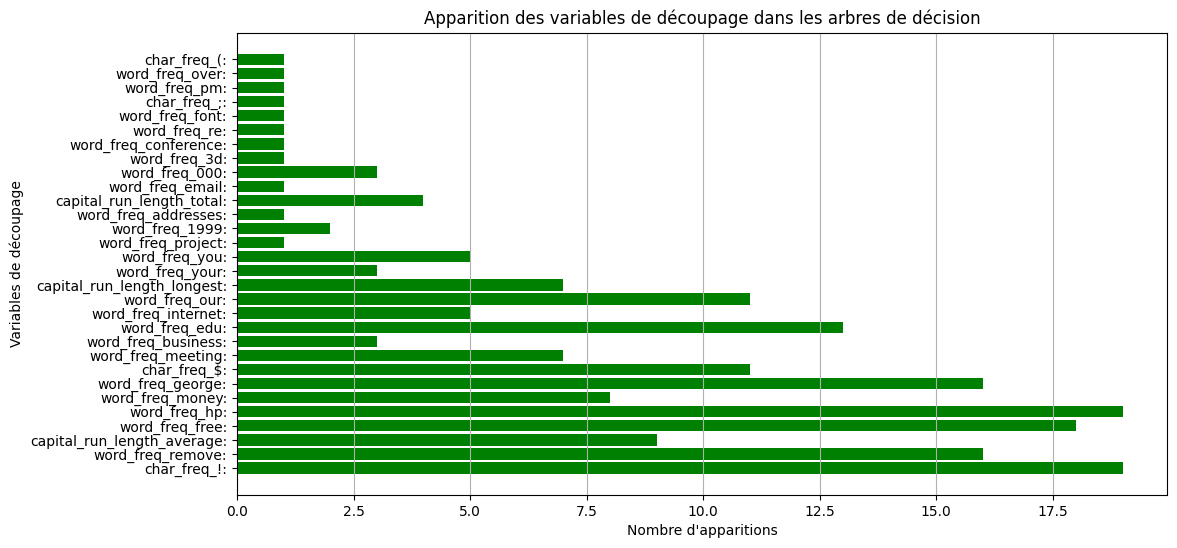

In [ ]:
from collections import Counter

#  Compter le nombre d'apparitions des variables de découpage
variable_counter = Counter()

for splitting_vars in splitting_variables_list:
    variable_counter.update([var for var in splitting_vars if var is not None])

# nombre d'apparitions des variables de découpage
print("\nApparition des variables de découpage :")
for variable, count in variable_counter.items():
    print(f"{variable}: {count} fois")
variables = list(variable_counter.keys())
ap = list(variable_counter.values())

# Créer un graphique
plt.figure(figsize=(12, 6))
plt.barh(variables, ap, color='green')
plt.xlabel('Nombre d\'apparitions')
plt.ylabel('Variables de découpage')
plt.title('Apparition des variables de découpage dans les arbres de décision')
plt.grid(axis='x')
plt.show()

L'analyse des variables de découpage des arbres construits  met en évidence une hétérogénéité dans leur utilisation. Certaines variables, comme "char_freq_!" et "word_feq_remove" par exemple, se retrouvent fréquemment comme critères de décision, suggérant leur importance dans la discrimination des spams. Ces variables pourraient donc être priorisées dans le développement de stratégies de détection. A l'inverse, d'autres variables sont moins utilisées, ce qui peut indiquer une importance moindre pour la tâche de classification ou une redondance avec d'autres variables;c'est l'exemple de "word_freq_1999"

## Bagged Trees

On importe maintenant les données Boston depuis `sckit-learn` (voir description plus bas) :

In [ ]:
from sklearn.datasets import load_boston
from sklearn.tree import DecisionTreeRegressor
boston = load_boston()

ImportError: 
`load_boston` has been removed from scikit-learn since version 1.2.

The Boston housing prices dataset has an ethical problem: as
investigated in [1], the authors of this dataset engineered a
non-invertible variable "B" assuming that racial self-segregation had a
positive impact on house prices [2]. Furthermore the goal of the
research that led to the creation of this dataset was to study the
impact of air quality but it did not give adequate demonstration of the
validity of this assumption.

The scikit-learn maintainers therefore strongly discourage the use of
this dataset unless the purpose of the code is to study and educate
about ethical issues in data science and machine learning.

In this special case, you can fetch the dataset from the original
source::

    import pandas as pd
    import numpy as np

    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
    data = np.hstack([raw_df.values[:

In [ ]:
# Instead of using load_boston:
# from sklearn.datasets import load_boston
# boston = load_boston()

# Use fetch_california_housing as an alternative:
from sklearn.datasets import fetch_california_housing
boston= fetch_california_housing()

# You may need to adjust your code to use the 'housing' variable
# instead of 'boston', as they have different structures.
# For example, if you were accessing data like this:
# X = boston.data
# y = boston.target
# You would now access it like this:
X_Bost_Bost = boston.data
Y_Bost= boston.target
print(shape(X_Bost_Bost))

(20640, 8)


In [ ]:

# Use fetch_california_housing as an alternative:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()
X_Bost_Bost = housing.data
Y_Bost= housing.target
print(shape(X_Bost_Bost))

(20640, 8)


In [ ]:
X_Bost = boston.data
Y_Bost = boston.target
print(shape(X_Bost))

In [ ]:
print(boston.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

> Séparer les données en deux échantillons apprentissage et test (80% - 20%).

In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets (80% - 20%)
X_train, X_test, Y_train, Y_test = train_test_split(X_Bost_Bost, Y_Bost, test_size=0.2, random_state=42)

> Construire (sans utiliser `BaggingRegressor()`) un bagged tree avec 20 échantillons bootstrap et donner la prédiction sur l'échantillon test. On pourra utiliser la fonction [`resample`](https://scikit-learn.org/stable/modules/generated/sklearn.utils.resample.html).

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils import resample
import numpy as np

# Number of bootstrap samples
n_estimators = 20

# Create a list to store the individual tree predictions
tree_predictions = []

# Bootstrap and train trees
for i in range(n_estimators):
    # Resample the training data with replacement
    X_bootstrap, Y_bootstrap = resample(X_train, Y_train, random_state=i)

    # Create and train a decision tree regressor
    tree = DecisionTreeRegressor()
    tree.fit(X_bootstrap, Y_bootstrap)

    # Make predictions on the test set
    tree_pred = tree.predict(X_test)

    # Store the predictions
    tree_predictions.append(tree_pred)

# Average the predictions to get the final prediction
bagged_pred = np.mean(tree_predictions, axis=0)

Avec sckit-learn, les performances en régression sont évaluées par défaut via le score du $R^2$ (coefficient d'ajustement ou coefficient de détermination). Ce score donne une mesure de la qualité de la prédiction :

$$
R^{2}=1- \frac {\sum _{i=1}^{n}(y_{i}-{\hat {y_{i}}})^{2}}{\sum _{i=1}^{n}(y_{i}-{\bar {y}})^{2}} = 1- \frac { \frac 1n \sum _{i=1}^{n}(y_{i}-{\hat {y_{i}}})^{2}}{ var (Y)}.
$$
Un ajustement parfait correspond évidemment à $R^2 = 1$.

On reconnait un terme d'erreur quadratique au numérateur. On peut bien sûr calculer le score sur l'échantillon d'apprentissage ou sur l'échantillon test.

> Calculer ce score pour la prédiction précédente.

In [ ]:
from sklearn.metrics import r2_score

# Calculate the R-squared score
r2 = r2_score(Y_test, bagged_pred)

# Print the R-squared score
print("R-squared score:", r2)

R-squared score: 0.79763307344164


> Construire de même un bagged tree en utilsant cette fois directement la fonction `BaggingRegressor()` (voir [ici](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingRegressor.html)), avec 20 arbres. Calculer la prédiction sur l'échantillon test et le score associé.

In [ ]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

# Create a BaggingRegressor with 20 DecisionTreeRegressor base estimators
# In older versions of scikit-learn, the 'base_estimator' argument might be named 'estimator'
# instead. If upgrading scikit-learn is not an option, try replacing 'base_estimator' with 'estimator'.
bagging_regressor = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=20, random_state=42)

# Fit the BaggingRegressor to the training data
bagging_regressor.fit(X_train, Y_train)

# Make predictions on the test set
bagging_pred = bagging_regressor.predict(X_test)

# Calculate the R-squared score
r2_bagging = r2_score(Y_test, bagging_pred)

# Print the R-squared score
print("R-squared score (BaggingRegressor):", r2_bagging)

R-squared score (BaggingRegressor): 0.7983451219477362


On peut retrouver les arbres qui forment ce bagged tree:

In [ ]:
print(bagTree.estimators_)

> Vérifier qu'il est possible d'accéder à tous les arbres du BaggingRegressor, par exemple donner la prédiction du deuxième arbre sur les données de test.

In [ ]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
from sklearn.tree import plot_tree  # For visualization
import matplotlib.pyplot as plt


# Create a BaggingRegressor with 20 DecisionTreeRegressor base estimators
bagging_regressor = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=20, random_state=42)

# Fit the BaggingRegressor to the training data
bagging_regressor.fit(X_train, Y_train)

# Access individual trees
individual_trees = bagging_regressor.estimators_

# Example: Visualize the first tree (optional)
plt.figure(figsize=(12, 8))
# Assuming you have a list of feature names called 'feature_names'
# If X_train was originally a DataFrame called 'df', you can get the feature names using df.columns.tolist()
feature_names = ['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8']  # Replace with your actual feature names
plot_tree(individual_trees[0], filled=True, feature_names=feature_names)
plt.show()

# You can now iterate through individual_trees and analyze them as needed.
# For example, you can print their depth, number of nodes, etc.
for i, tree in enumerate(individual_trees):
    print(f"Tree {i + 1}: Depth = {tree.get_depth()}, Number of nodes = {tree.get_n_leaves()}")

# ... (rest of your code)

> Il est bien sûr possible de faire du bagging avec d'autres prédicteurs que les arbres. Consulter la documentation de la fonction `BaggingRegressor()` pour ajuster sur les données un bagging de 20 regresseurs linéaires.

In [ ]:
### TODO ###